# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Sania
- **Student ID:** 023-24-277
- **Section:** H
- **GitHub:** https://github.com/saniamirani
- **Kaggle:**  https://www.kaggle.com/saniam58
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [3]:
df=pd.read_csv("Mall_Customers.csv")
print(df.head())
df=df.rename(columns={'Annual Income (k$)': 'Income', 
                      'Spending Score (1-100)': 'Spending'})
print(df.shape)
display(df.head())

print(df.isnull().sum(), "\n")
print("Number of duplicate rows: ",df.duplicated().sum(), "\n")
print(df["Gender"].value_counts(), "\n")
print("Age Feature Description:", "\n" ,df["Age"].describe(), "\n")
print("Income Feature Description:", "\n" ,df["Income"].describe(), "\n")
print("Spending Feature Description:", "\n" ,df["Spending"].describe(), "\n")


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)


,CustomerID,Gender,Age,Income,Spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64 

Number of duplicate rows:  0 

Gender
Female    112
Male       88
Name: count, dtype: int64 

Age Feature Description: 
 count    200.000000
mean      38.850000
std       13.969007
min       18.000000
25%       28.750000
50%       36.000000
75%       49.000000
max       70.000000
Name: Age, dtype: float64 

Income Feature Description: 
 count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Income, dtype: float64 

Spending Feature Description: 
 count    200.000000
mean      50.200000
std       25.823522
min        1.000000
25%       34.750000
50%       50.000000
75%       73.000000
max       99.000000
Name: Spending, dtype: float64 



### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

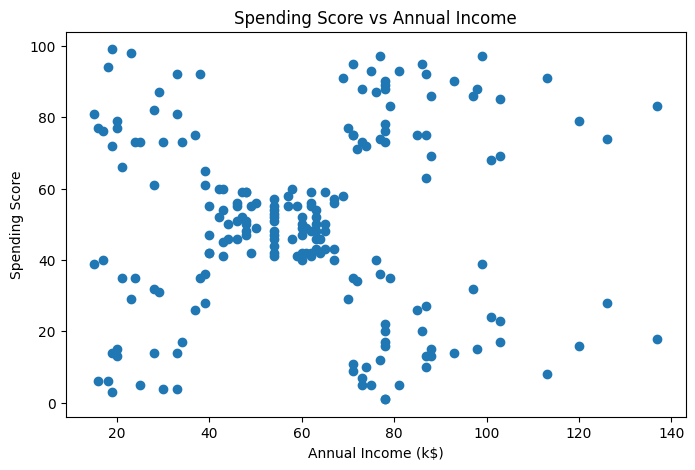

In [4]:
plt.figure(figsize=(8,5))
plt.scatter(df["Income"],df["Spending"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Spending Score vs Annual Income")
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a) Apparently there are 5 groups.
Group 1: low income, low spending
Group 2: low income, high spending
Group 3: medium income, medium spending
Group 4: high income, low spending
Group 5: high income, high spending

(b) It is not fixed that classification has to produced only one kind of result. Therefore, accuracy can not be used. Clustering is Unsupervised Learning. The goal is to find groups in the data, not to predict a known outcome.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [5]:
x=np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids= np.array([4.0, 11.0])

for iteration in range(1,101):
    distances=np.abs(x[:, None] - centroids[None, :])
    groups = distances.argmin(axis=1)
    
    new_centroids = centroids.copy()
    
    for k in range(2):
        if np.any(groups == k):
            new_centroids[k] = x[groups==k].mean()
    print(f"Iteration {iteration}")
    for k in range(2):
        print(f"Cluster C{k+1}:", x[groups == k])
    print("New centroids:", new_centroids)

    if np.allclose(new_centroids, centroids):
        centroids = new_centroids
        break
    centroids = new_centroids

inertia = np.sum((x - centroids[groups])**2)
print("\nFinal centroids:", centroids)
print("Inertia:", inertia)

print(groups)
    

Iteration 1
Cluster C1: [2. 4. 3.]
Cluster C2: [10. 12. 20. 30. 11. 25.]
New centroids: [ 3. 18.]
Iteration 2
Cluster C1: [ 2.  4. 10.  3.]
Cluster C2: [12. 20. 30. 11. 25.]
New centroids: [ 4.75 19.6 ]
Iteration 3
Cluster C1: [ 2.  4. 10. 12.  3. 11.]
Cluster C2: [20. 30. 25.]
New centroids: [ 7. 25.]
Iteration 4
Cluster C1: [ 2.  4. 10. 12.  3. 11.]
Cluster C2: [20. 30. 25.]
New centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Inertia: 150.0
[0 0 0 0 0 1 1 0 1]


### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [6]:
def my_kmeans(X, init_centroids, max_iter=100):
    X= np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()

    for iteration in range(1, max_iter +1):
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :])**2).sum(axis=2))
        labels= distances.argmin(axis=1)

        new_centroids=centroids.copy()
        for k in range(len(centroids)):
            if np.any(labels == k):
                new_centroids[k]=X[labels==k].mean(axis=0)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break
        centroids = new_centroids
    inertia = np.sum((X-centroids[labels])**2)
    
    return labels, centroids, inertia, iteration
X1 = x.reshape(-1, 1)
labels1, centers1, inertia1, iterations1 = my_kmeans(X1, [[4], [11]])

print("Own function centroids:", centers1.ravel())
print("Own function inertia:", inertia1)
print("Iterations:", iterations1)


Own function centroids: [ 7. 25.]
Own function inertia: 150.0
Iterations: 4


In [7]:
X2= df[["Income", "Spending"]].values
initial_centroids = X2[:5]

my_labels, my_centers, my_inertia, my_iterations= my_kmeans(X2, initial_centroids)

sk_model = KMeans(
    n_clusters=5, 
    init=initial_centroids,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    max_iter=100
)
sk_model.fit(X2)

print("\nOwn K-Means inertia: ", round(my_inertia, 2))
print("Scikit-learn inertia: ", round(sk_model.inertia_, 2))
print("\nOwn centroids: \n", np.round(my_centers, 2))
print("\nScikit-learn centroids: \n", np.round(sk_model.cluster_centers_, 2))



Own K-Means inertia:  44448.46
Scikit-learn inertia:  44448.46

Own centroids: 
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]

Scikit-learn centroids: 
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a) At first point had lesser distance to cluster 2 that is 1 compared to 6 to cluster 1. The updated centroids after first iteration are 3 and 18. And point 10 has lesser distance to cluster 1 that is 7 compared to 8 to cluster 2 so it was assigned to cluster 1.

(b) When updated centroids match previous centroids, the loop breaks.

(c)Everything was same in both.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

,K,Inertia,Silhouette
0,2,181363.6,0.297
1,3,106348.4,0.468
2,4,73679.8,0.493
3,5,44448.5,0.554
4,6,37233.8,0.540
5,7,30241.3,0.529
6,8,25036.4,0.455
7,9,21916.8,0.456
8,10,20072.1,0.441


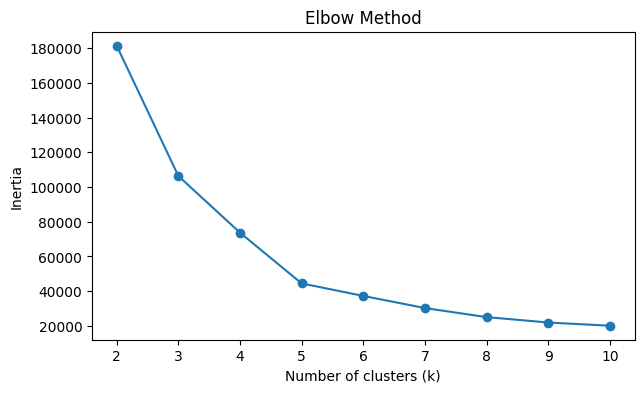

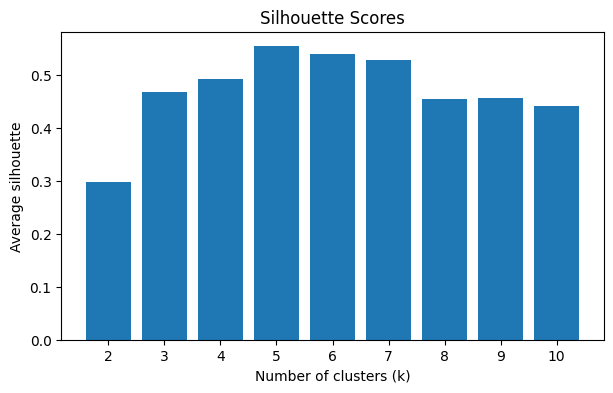

K with highest silhouette: 5


In [8]:
results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10,  random_state= SEED)
    labels = model.fit_predict(X2)
    results.append({
        "K" : k,
        "Inertia": np.round(model.inertia_, 1), 
        "Silhouette": np.round(silhouette_score(X2, labels), 3)
    })

results_df=pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(7,4))
plt.plot(results_df["K"], results_df["Inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.show()

plt.figure(figsize=(7,4))
plt.bar(results_df["K"], results_df["Silhouette"])
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette")
plt.title("Silhouette Scores")
plt.xticks(range(2, 11))
plt.show()

best_k = int(results_df.loc[results_df["Silhouette"].idxmax(), "K"])
print("K with highest silhouette:", best_k)

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [9]:
model5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = model5.fit_predict(X2)

def silhouette_by_hand(X, labels, point_index):
    point= X[point_index]
    own_cluster = labels[point_index]

    own_points= X[labels == own_cluster]
    own_distances = np.sqrt(((own_points - point) ** 2).sum(axis=1))
    own_distances = own_distances[labels[labels == own_cluster] != own_cluster] if False else own_distances
    a = own_distances[~np.all(own_points == point, axis=1)].mean()

    other_means=[]
    for cluster in np.unique(labels):
        if cluster != own_cluster:
            other_points = X[labels == cluster]
            distances = np.sqrt(((other_points - point) ** 2).sum(axis=1))
            other_means.append(distances.mean())

    b= min(other_means)
    s= (b-a) / max(a,b)
    return a, b, s

a, b, s = silhouette_by_hand(X2, labels5, 0)
print("a:", a)
print("b:", b)
print("Silhouette by hand:", s)
print("Silhouette_samples:", silhouette_samples(X2, labels5)[0])

a: 24.64044215163639
b: 42.26526678748377
Silhouette by hand: 0.41700493041881637
Silhouette_samples: 0.4170049304188163


In [10]:
labels5[0]

np.int32(4)

**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

(a) Elbow and Silhouette method both suggest same k that is 5.

(b The silhouette score of customer 1 is 0.417. We can't tell where customer sits from silhouette score.

(c) Inertia keeps on getting smaller with bigger K and bigger K increases the complexity of algorithm.

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [21]:
random_inertias = []
plus_inertias= []

for seed in range(30):
    random_model = KMeans(
        n_clusters=5, init="random", n_init=1, random_state=seed)
    random_model.fit(X2)
    random_inertias.append(random_model.inertia_)

    plus_model = KMeans(
        n_clusters = 5, init ="k-means++", n_init=10, random_state= seed
    )
    plus_model.fit(X2)
    plus_inertias.append(plus_model.inertia_)

def inertia_summary(values):
    rounded = np.round(values, 1)
    print("Lowest inertia:", min(values))
    print("Highest inertia:", max(values))
    print("Distinct values:", len(np.unique(rounded)))

print("init='random', n_init=1")
inertia_summary(random_inertias)

print("\ninit='k-means++', n_init=10")
inertia_summary(plus_inertias)

init='random', n_init=1
Lowest inertia: 44448.45544793371
Highest inertia: 91761.97619211908
Distinct values: 14

init='k-means++', n_init=10
Lowest inertia: 44448.45544793371
Highest inertia: 44448.45544793371
Distinct values: 1


**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a) KMeans with init="random" produced 14 distinct values and with init="k-means++" produced only 1 distinct value.

(b) Random centroid initialization causes the algorithm to get stuck in different local minima depending on where the initial centroids are placed.

(c) k-means++ intelligently spreads out initial centroids to avoid poor local optima, and n_init=10 runs multiple times to pick the best result, consistently yielding the lowest inertia of 44448.46.

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

ARI: raw k$ vs raw dollars: 0.48965682118947657
ARI: scaled k$ vs scaled dollars: 1.0


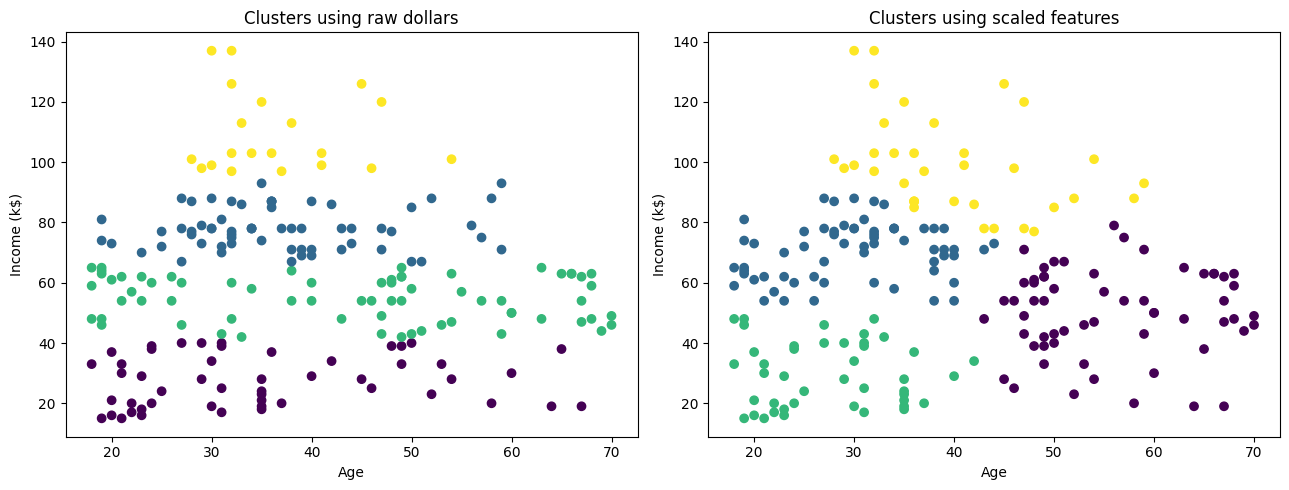

In [33]:
X_age_income = df[["Age", "Income"]].values
X_age_dollars = df[["Age", "Income"]].copy()
X_age_dollars["Income"] *= 1000
X_age_dollars = X_age_dollars.values

raw_k_model = KMeans(n_clusters =4, n_init=10, random_state=SEED)
raw_k_labels = raw_k_model.fit_predict(X_age_income)

raw_dollar_model = KMeans(n_clusters= 4, n_init=10, random_state=SEED)
raw_dollar_labels = raw_dollar_model.fit_predict(X_age_dollars)

scaler_k = StandardScaler()
X_scaled_k = scaler_k.fit_transform(X_age_income)

scaler_dollars = StandardScaler()
X_scaled_dollars= scaler_dollars.fit_transform(X_age_dollars)

scaled_k_model = KMeans(n_clusters=4, n_init=10, random_state=SEED)
scaled_k_labels= scaled_k_model.fit_predict(X_scaled_k)

scaled_dollar_model= KMeans(n_clusters=4, n_init=10, random_state=SEED)
scaled_dollar_labels =scaled_dollar_model.fit_predict(X_scaled_dollars)

print("ARI: raw k$ vs raw dollars:",
      adjusted_rand_score(raw_k_labels, raw_dollar_labels))
print("ARI: scaled k$ vs scaled dollars:",
      adjusted_rand_score(scaled_k_labels, scaled_dollar_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["Age"], df["Income"], c=raw_dollar_labels)
axes[0].set_title("Clusters using raw dollars")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")

axes[1].scatter(df["Age"], df["Income"], c=scaled_k_labels)
axes[1].set_title("Clusters using scaled features")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a) Income dominated the Euclidean distance due to its inflated magnitude; scaling equalized both features' influence (ARI: 1.0).

(b) Always scale features when they have different units or varying magnitudes, as distance-based algorithms are sensitive to scale.

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

Original data
Cluster sizes (original cluster IDs):
 0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Centroids sorted by income:
 [[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]

With extra customer
Cluster sizes (original cluster IDs):
 0    100
1      1
2     23
3     39
4     38
Name: count, dtype: int64
Centroids sorted by income:
 [[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]


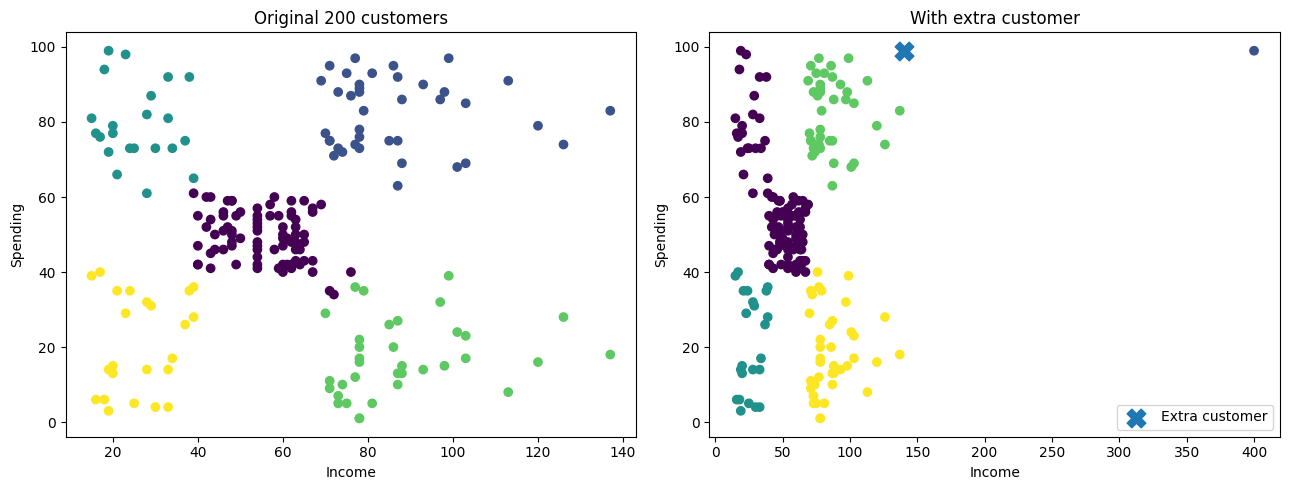

In [37]:
extra_customer = np.array([[400, 99]], dtype=float)
X2_with_outlier = np.vstack([X2, extra_customer])

original_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
original_labels = original_model.fit_predict(X2)

outlier_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
outlier_labels = outlier_model.fit_predict(X2_with_outlier)

def sorted_centers_and_sizes(labels, centers):
    order = np.argsort(centers[:, 0])
    sizes = pd.Series(labels).value_counts().reindex(range(len(centers)), fill_value=0)
    print("Cluster sizes (original cluster IDs):\n", sizes)
    print("Centroids sorted by income:\n", centers[order])

print("Original data")
sorted_centers_and_sizes(original_labels, original_model.cluster_centers_)

print("\nWith extra customer")
sorted_centers_and_sizes(outlier_labels, outlier_model.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X2[:, 0], X2[:, 1], c=original_labels)
axes[0].set_title("Original 200 customers")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")

axes[1].scatter(X2_with_outlier[:, 0], X2_with_outlier[:, 1], c=outlier_labels)
axes[1].scatter(400, 99, marker="X", s=180, label="Extra customer")
axes[1].set_title("With extra customer")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")
axes[1].legend()

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [38]:
real_distances = original_model.transform(X2).min(axis=1)
extra_distance = original_model.transform(extra_customer).min()

threshold = real_distances.mean() + 3 * real_distances.std()

print("Mean real-customer distance:", real_distances.mean())
print("Standard deviation:", real_distances.std())
print("Threshold (mean + 3 std):", threshold)
print("Extra customer distance:", extra_distance)
print("Extra customer flagged:", extra_distance > threshold)

flagged_real = real_distances > threshold
print("Number of real customers flagged:", flagged_real.sum())
print("Flagged real-customer row indexes:", np.where(flagged_real)[0])

Mean real-customer distance: 13.020126350791761
Standard deviation: 7.260756644392302
Threshold (mean + 3 std): 34.80239628396867
Extra customer distance: 313.9152649312717
Extra customer flagged: True
Number of real customers flagged: 4
Flagged real-customer row indexes: [196 197 198 199]


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

(a) It pulled the cluster centroid toward itself and distorted the cluster boundaries.

(b) Yes, it caught the extra customer; the flagged real customers are simply unusual individuals, not errors.

(c) Drop them or cap them; risk: losing valuable rare information or biasing the data.

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [39]:
final_model = KMeans(n_clusters=best_k, n_init=10, random_state=SEED)
df["Cluster"] = final_model.fit_predict(X2)

cols = ["Age", "Income", "Spending"]
profile = df.groupby("Cluster")[cols].mean().round(2)
sizes = df["Cluster"].value_counts().sort_index()

profile.insert(0, "Size", sizes)
display(profile)

,Size,Age,Income,Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [40]:
def name_segment(row):
    income_level = "High income" if row["Income"] >= df["Income"].median() else "Low income"
    spending_level = "high spending" if row["Spending"] >= df["Spending"].median() else "low spending"
    return f"{income_level}, {spending_level}"

segment_names = {
    cluster: name_segment(profile.loc[cluster])
    for cluster in profile.index
}
df["Segment"] = df["Cluster"].map(segment_names)

marketing_actions = {
    cluster: (
        "Offer premium products and loyalty rewards."
        if "High income, high spending" == segment_names[cluster]
        else "Use targeted promotions suited to this customer group."
    )
    for cluster in profile.index
}

profile["Segment"] = pd.Series(segment_names)
profile["Marketing Action"] = pd.Series(marketing_actions)
display(profile)

output_columns = [
    "CustomerID", "Age", "Gender", "Income",
    "Spending", "Cluster", "Segment"
]
df[output_columns].to_csv("customer_segments.csv", index=False)
print("Saved customer_segments.csv")

,Size,Age,Income,Spending,Segment,Marketing Action
Cluster,,,,,,
0,81,42.72,55.30,49.52,"Low income, low spending",Use targeted promotions suited to this custome...
1,39,32.69,86.54,82.13,"High income, high spending",Offer premium products and loyalty rewards.
2,22,25.27,25.73,79.36,"Low income, high spending",Use targeted promotions suited to this custome...
3,35,41.11,88.20,17.11,"High income, low spending",Use targeted promotions suited to this custome...
4,23,45.22,26.30,20.91,"Low income, low spending",Use targeted promotions suited to this custome...


Saved customer_segments.csv


**Executive Summary** (4–6 lines)

K=5 was selected based on the elbow method's inflection point and silhouette score peaks.

Segments comprise low income/low spending (sizes 81 and 23), high income/high spending (size 39), low income/high spending (size 22), and high income/low spending (size 35).

Features were standardized using StandardScaler, and outliers were managed via distance thresholds.

A primary limitation is that K-Means assumes spherical clusters of equal variance, which can misclassify irregular groupings.

---